# 14 — 1D-CNN on the raw windows

No hand-crafted features: the filtered 200 ms windows themselves (`features.names: [RAW]`, 16 channels
x 40 samples, z-scored per channel and sample), into three Conv1d-ReLU layers (32, 32, 64 filters, kernel 5, strides
1/2/2), mean over time and a linear layer (`src/nn.py`, `CNN`, ~25k parameters). Trained on the GPU when there is one
(`device: auto`), inference numpy.

Calibration (`loso`): fine-tunes the output layer.

Same protocol as `10`: DB5 exercise 1, train on repetitions 1–4, test on 5–6, every regime. Writes `runs/notebooks/cnn.json` for `15`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src import report

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
FEATURES = {"features": {"names": ["RAW"]}, "dataset": {"out_dir": "data/processed/raw"}}
DECODER = {"decoder": {"name": "cnn", "params": {"channels": 16}}}
cfg, *data = report.features(FEATURES)
X, y, columns, info = data
print(f"{len(y)} windows x {X.shape[1]} features")

140145 windows x 640 features


## Every regime

In [3]:
summary = report.run_regimes({**FEATURES, **DECODER}, data)
latency = report.latency_us({**FEATURES, **DECODER}, data)
report.save(DECODER["decoder"]["name"], summary, latency)
print(f"decoder latency: {latency:.0f} µs per window")

per_user balanced 0.596 | macro-F1 0.556 | 109 s


pooled   balanced 0.512 | macro-F1 0.474 | 31 s


loso     balanced 0.376 | macro-F1 0.359 | 497 s


decoder latency: 142 µs per window


Against the LDA baseline (from `10`):

In [4]:
summaries = report.load_all()
names = [n for n in ("lda", DECODER["decoder"]["name"]) if n in summaries]
report.table({n: summaries[n] for n in names}).round(3)

accuracy  balanced_accuracy  macro_f1  worst_user_balanced  \
decoder regime                                                                 
lda     per_user     0.810              0.643     0.653                0.566   
        pooled       0.730              0.461     0.467                0.291   
        loso         0.701              0.389     0.393                0.234   
cnn     per_user     0.738              0.596     0.556                0.519   
        pooled       0.683              0.512     0.474                0.387   
        loso         0.623              0.376     0.359                0.251   

                  switches_per_s  latency_us  evaluation_s  
decoder regime                                              
lda     per_user           2.468       7.375         0.940  
        pooled             3.519       7.375         0.156  
        loso               3.690       7.375         1.876  
cnn     per_user           4.312     142.208       109.417  
        pooled             5.097     142.208        30.703  
        loso               5.648     142.208       497.180

## Calibration effort

Dashed: a new decoder per subject from *n* seconds per class. Solid: the decoder of the other nine subjects, adapted with them.

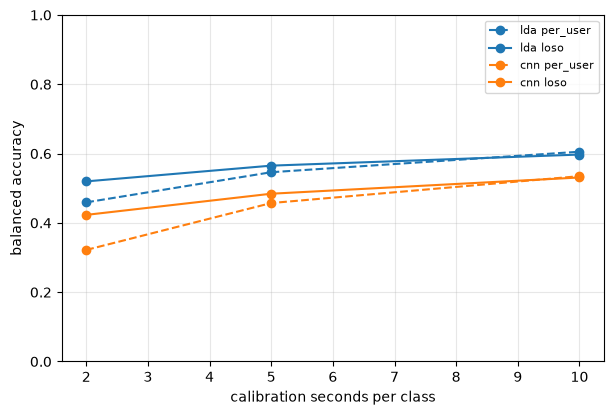

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
report.plot_calibration(ax, {n: summaries[n] for n in names})

## Confusions (per_user)

per_user    0.839
pooled      0.803
loso        0.795
Name: rest recall, dtype: float64

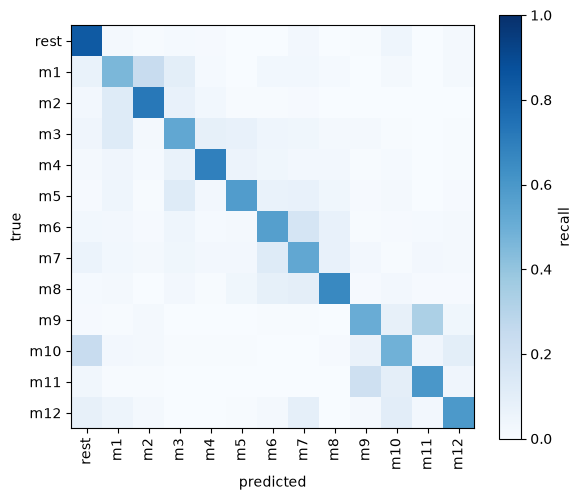

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = report.plot_confusion(ax, summary["per_user"]["y_true"], summary["per_user"]["y_pred"], info["label_names"])
fig.colorbar(im, label="recall")
pd.Series({regime: s["recall"]["rest"] for regime, s in summary.items()}, name="rest recall").round(3)